# Imports

In [29]:
import keras
import datasets
import numpy as np
import pandas as pd
import transformers
import sklearn.metrics
import tensorflow as tf
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

In [20]:
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

print("Available GPUs:", gpus)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [13]:
raw_dataset = datasets.load_dataset('google-research-datasets/go_emotions', name='raw', split='train')

In [14]:
raw_dataset

Dataset({
    features: ['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id', 'created_utc', 'rater_id', 'example_very_unclear', 'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral'],
    num_rows: 211225
})

In [15]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

In [16]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

In [17]:
PAD_ID = 0
VOCAB_SIZE = len(tokenizer) + 1

In [21]:
MAX_SAMPLES = 30000
FIXED_LENGTH = 64
VARIABLE_MAX_LENGTH = 128
BATCH_SIZE = 64

if MAX_SAMPLES is not None:
    raw_dataset = raw_dataset.shuffle(seed=SEED).select(range(min(MAX_SAMPLES, len(raw_dataset))))

missing = set(emotions) - set(raw_dataset.column_names)
if missing:
    raise ValueError(f'Missing emotion columns in raw dataset: {sorted(missing)}')

texts = raw_dataset['text']
labels = np.column_stack([raw_dataset[e] for e in emotions]).astype(np.float32)
assert labels.shape == (len(texts), len(emotions))
print('Samples:', len(texts), 'label shape:', labels.shape)
print('Label prevalence:', dict(zip(emotions, labels.mean(axis=0).round(3))))

idx_train, idx_other = sklearn.model_selection.train_test_split(
    np.arange(len(texts)), test_size=0.2, random_state=SEED, shuffle=True
)
idx_val, idx_test = sklearn.model_selection.train_test_split(
    idx_other, test_size=0.5, random_state=SEED, shuffle=True
)

texts = [str(text) for text in texts]

encoded = tokenizer(
    texts, add_special_tokens=False, truncation=True,
    max_length=VARIABLE_MAX_LENGTH
)['input_ids']

encoded = [np.asarray([token_id + 1 for token_id in (ids or [tokenizer.eos_token_id])],
                      dtype=np.int32) for ids in encoded]

def make_tf_dataset(indices, variant: str, shuffle: bool = False):
    if variant not in ('variable', 'fixed'):
        raise ValueError('variant must be variable or fixed')
    def generator():
        for i in indices:
            x = encoded[int(i)]
            if variant == 'fixed':
                x = x[:FIXED_LENGTH]
            yield x, labels[int(i)]

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(None,), dtype=tf.int32),
            tf.TensorSpec(shape=(len(emotions),), dtype=tf.float32),
        ),
    )
    if shuffle:
        ds = ds.shuffle(min(len(indices), 10000), seed=SEED, reshuffle_each_iteration=True)
    padded_shape = [None] if variant == 'variable' else [FIXED_LENGTH]
    ds = ds.padded_batch(
        BATCH_SIZE, padded_shapes=(padded_shape, [len(emotions)]),
        padding_values=(tf.constant(PAD_ID, tf.int32), tf.constant(0, tf.float32)),
    )
    return ds.prefetch(tf.data.AUTOTUNE)

splits = {
    kind: {
        'train': make_tf_dataset(idx_train, kind, shuffle=True),
        'val': make_tf_dataset(idx_val, kind),
        'test': make_tf_dataset(idx_test, kind),
    }
    for kind in ('variable', 'fixed')
}
for kind in splits:
    x_batch, y_batch = next(iter(splits[kind]['train']))
    print(kind, x_batch.shape, y_batch.shape)

Samples: 30000 label shape: (30000, 28)
Label prevalence: {'admiration': np.float32(0.081), 'amusement': np.float32(0.047), 'anger': np.float32(0.038), 'annoyance': np.float32(0.062), 'approval': np.float32(0.083), 'caring': np.float32(0.029), 'confusion': np.float32(0.035), 'curiosity': np.float32(0.045), 'desire': np.float32(0.019), 'disappointment': np.float32(0.038), 'disapproval': np.float32(0.054), 'disgust': np.float32(0.026), 'embarrassment': np.float32(0.012), 'excitement': np.float32(0.027), 'fear': np.float32(0.015), 'gratitude': np.float32(0.055), 'grief': np.float32(0.004), 'joy': np.float32(0.038), 'love': np.float32(0.038), 'nervousness': np.float32(0.009), 'optimism': np.float32(0.04), 'pride': np.float32(0.006), 'realization': np.float32(0.042), 'relief': np.float32(0.006), 'remorse': np.float32(0.011), 'sadness': np.float32(0.031), 'surprise': np.float32(0.025), 'neutral': np.float32(0.263)}


I0000 00:00:1793546711.297048      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793546711.307217      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


variable (64, 46) (64, 28)
fixed (64, 64) (64, 28)


# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [22]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [23]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    n_stacks: int = 1,
    bidirectional: bool = False,
    name: str | None = None,
    cell_type: type[keras.layers.Layer] = keras.layers.LSTMCell
) -> keras.Model:
    '''Creates a model with RNN architecture for sequence multilabel classification.

    Arguments:
        units: dimensionality of RNN cells
        n_tokens: number of tokens in the tokenizer dictionary
        n_labels: number of labels to be predicted
        n_stacks: number of RNN cells in the stack (1 -- no stacking)
        bidirectional: whether or not the model is bidirectional
        name: the model name
        cell_type: type of a cell to use, either keras.layers.LSTMCell or keras.layers.GRUCell

    Returns:
        The model'''
    
    if n_stacks < 1:
        raise ValueError('n_stacks must be >= 1')
        
    if cell_type not in (keras.layers.LSTMCell, keras.layers.GRUCell):
        raise ValueError('cell_type must be keras.layers.LSTMCell or GRUCell')
        
    rnn_cls = keras.layers.LSTM if cell_type is keras.layers.LSTMCell else keras.layers.GRU
    inputs = keras.Input(shape=(None,), dtype='int32', name='token_ids')
    x = keras.layers.Embedding(n_tokens, 64, mask_zero=True, name='embedding')(inputs)
    
    for depth in range(n_stacks):
        is_last = depth == n_stacks - 1
        recurrent = rnn_cls(units, return_sequences=not is_last, name=f'{rnn_cls.__name__.lower()}_{depth+1}')
        if bidirectional:
            recurrent = keras.layers.Bidirectional(recurrent, name=f'bidir_{depth+1}')
        x = recurrent(x)
        if not is_last:
            x = keras.layers.Dropout(0.2)(x)
            
    x = keras.layers.Dropout(0.3)(x)
    outputs = keras.layers.Dense(n_labels, activation='sigmoid', name='emotions')(x)
    
    return keras.Model(inputs, outputs, name=name or 'rnn_classifier')

# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [24]:
ARCHITECTURES = [
    dict(name='simple', n_stacks=1, bidirectional=False),
    dict(name='stacked', n_stacks=2, bidirectional=False),
    dict(name='bidirectional', n_stacks=1, bidirectional=True),
    dict(name='stacked_bidirectional', n_stacks=2, bidirectional=True),
]
UNITS = 64
EPOCHS = 3
LEARNING_RATE = 1e-3
CELL_TYPE = keras.layers.GRUCell

def build_models(cell_type=CELL_TYPE):
    return [get_model(
        units=UNITS, n_tokens=VOCAB_SIZE, n_labels=len(emotions),
        name=get_name(spec['name'], cell_type.__name__.replace('Cell', '').lower()),
        bidirectional=spec['bidirectional'], n_stacks=spec['n_stacks'],
        cell_type=cell_type,
    ) for spec in ARCHITECTURES]

models = build_models()
for model in models:
    print(model.name, 'params:', model.count_params())

simple_gru params: 3243292
stacked_gru params: 3268252
bidirectional_gru params: 3270044
stacked_bidirectional_gru params: 3344540


**Multilabel classification** means each example can have several emotions at once.
Use **binary cross-entropy** with independent sigmoid outputs (not softmax).
Track binary accuracy, but use **macro/micro ROC AUC** and F1 for comparison:
binary accuracy can look high even when rare emotions are missed.

In [25]:
def compile_model(model):
    model.compile(
        loss=keras.losses.BinaryCrossentropy(),
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        metrics=[
            keras.metrics.BinaryAccuracy(name='binary_accuracy'),
            keras.metrics.AUC(name='micro_roc_auc', curve='ROC', multi_label=False),
        ],
    )
    return model

for model in models:
    compile_model(model)

In [26]:
trained_models = {}
histories = {}
for variant in ('variable', 'fixed'):
    for spec in ARCHITECTURES:
        keras.backend.clear_session()
        model = compile_model(get_model(
            units=UNITS, n_tokens=VOCAB_SIZE, n_labels=len(emotions),
            name=get_name(spec['name'], variant),
            bidirectional=spec['bidirectional'], n_stacks=spec['n_stacks'],
            cell_type=CELL_TYPE,
        ))
        print(f'\nTraining {model.name}')
        history = model.fit(
            splits[variant]['train'], validation_data=splits[variant]['val'],
            epochs=EPOCHS, verbose=1,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor='val_loss', patience=2, restore_best_weights=True
            )],
        )
        trained_models[(variant, spec['name'])] = model
        histories[(variant, spec['name'])] = history.history
print('Trained models:', len(trained_models))


Training simple_variable
Epoch 1/3
    373/Unknown 13s 15ms/step - binary_accuracy: 0.9220 - loss: 0.2964 - micro_roc_auc: 0.5979

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - binary_accuracy: 0.9496 - loss: 0.2036 - micro_roc_auc: 0.6512 - val_binary_accuracy: 0.9583 - val_loss: 0.1563 - val_micro_roc_auc: 0.7310
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - binary_accuracy: 0.9577 - loss: 0.1644 - micro_roc_auc: 0.6963 - val_binary_accuracy: 0.9583 - val_loss: 0.1547 - val_micro_roc_auc: 0.7416
Epoch 3/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - binary_accuracy: 0.9579 - loss: 0.1604 - micro_roc_auc: 0.7151 - val_binary_accuracy: 0.9583 - val_loss: 0.1529 - val_micro_roc_auc: 0.7532

Training stacked_variable
Epoch 1/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - binary_accuracy: 0.9522 - loss: 0.1933 - micro_roc_auc: 0.6574 - val_binary_accuracy: 0.9583 - val_loss: 0.1558 - val_micro_roc_auc: 0.7315
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - binary_accuracy: 0.9578 - loss: 0.1634 - micro_roc_auc: 0.6994 - val_binary_accuracy: 0.9583 - val_loss: 0.1549 - val_micro_roc_auc: 0.7406
Epoch 3/3
3

# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [27]:
def dataset_to_numpy(ds):
    y_true, y_prob = [], []
    for xb, yb in ds:
        y_true.append(yb.numpy())
    return np.concatenate(y_true, axis=0)

def plot_roc_curve(
    X: np.ndarray,
    y: np.ndarray,
    model: keras.Model,
    ax: plt.Axes | None = None
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 7))
    probs = model.predict(X, verbose=0)
    scores = []
    for j, emotion in enumerate(emotions):
        if len(np.unique(y[:, j])) != 2:
            continue
        auc = sklearn.metrics.roc_auc_score(y[:, j], probs[:, j])
        scores.append(auc)
        sklearn.metrics.RocCurveDisplay.from_predictions(
            y[:, j], probs[:, j], ax=ax, name=f'{emotion} ({auc:.2f})',
            plot_chance_level=False,
        )
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    ax.set_title(f'{model.name}: macro ROC AUC = {np.mean(scores):.3f}')
    ax.legend(fontsize=7, ncol=2, loc='lower right')
    return float(np.mean(scores)) if scores else float('nan')

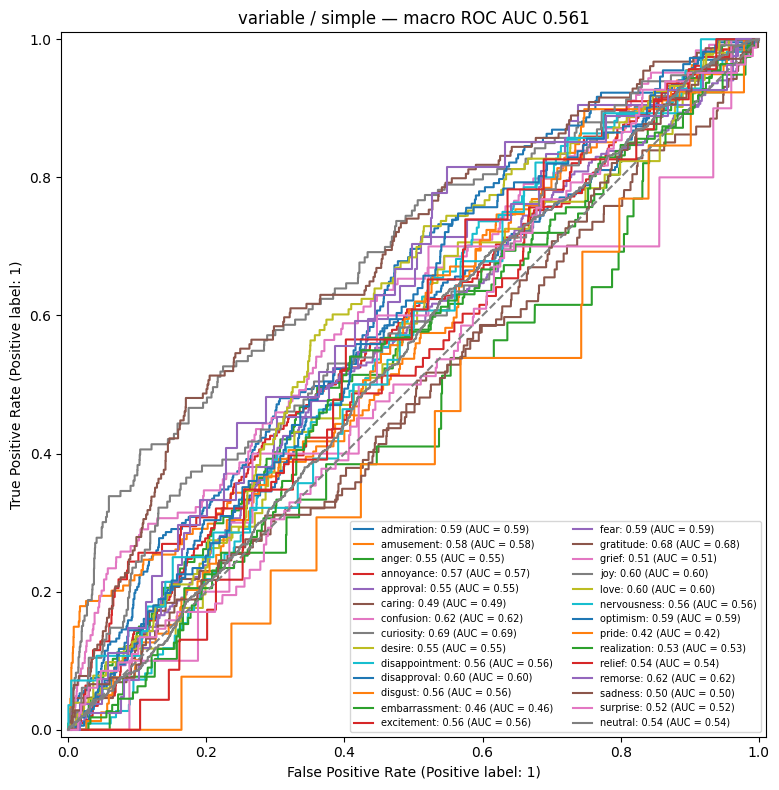

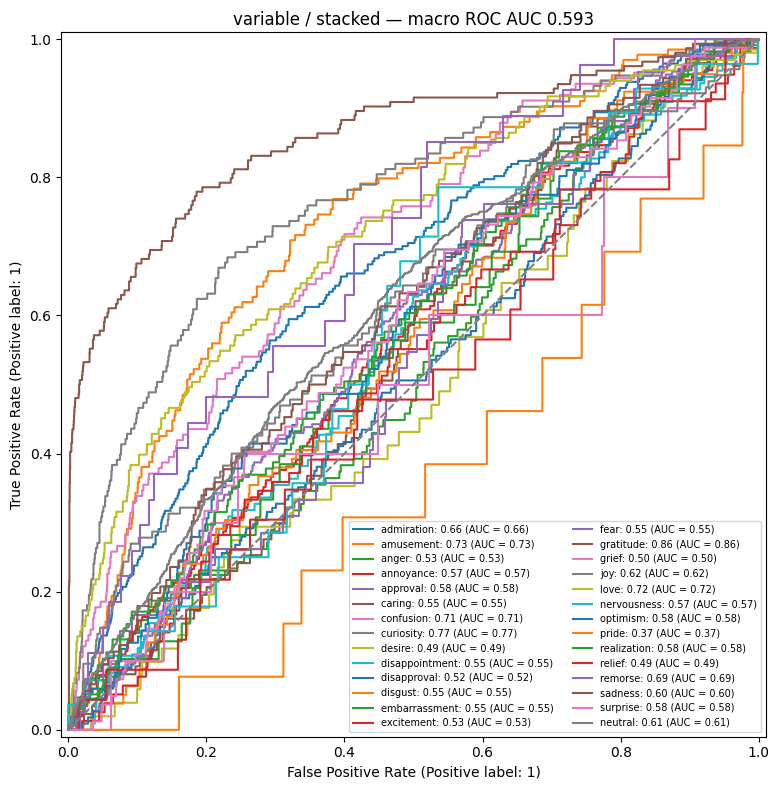

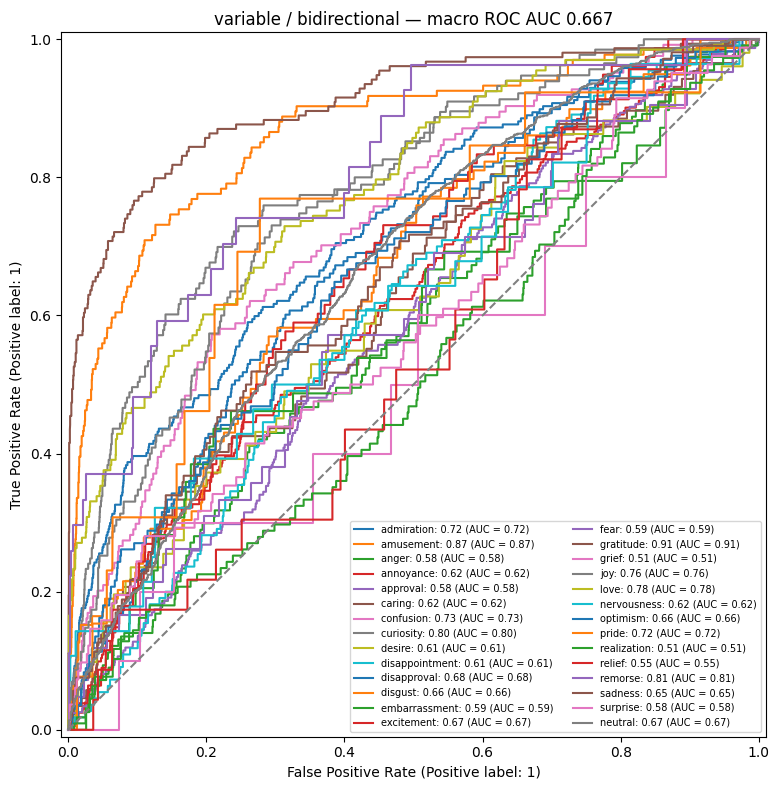

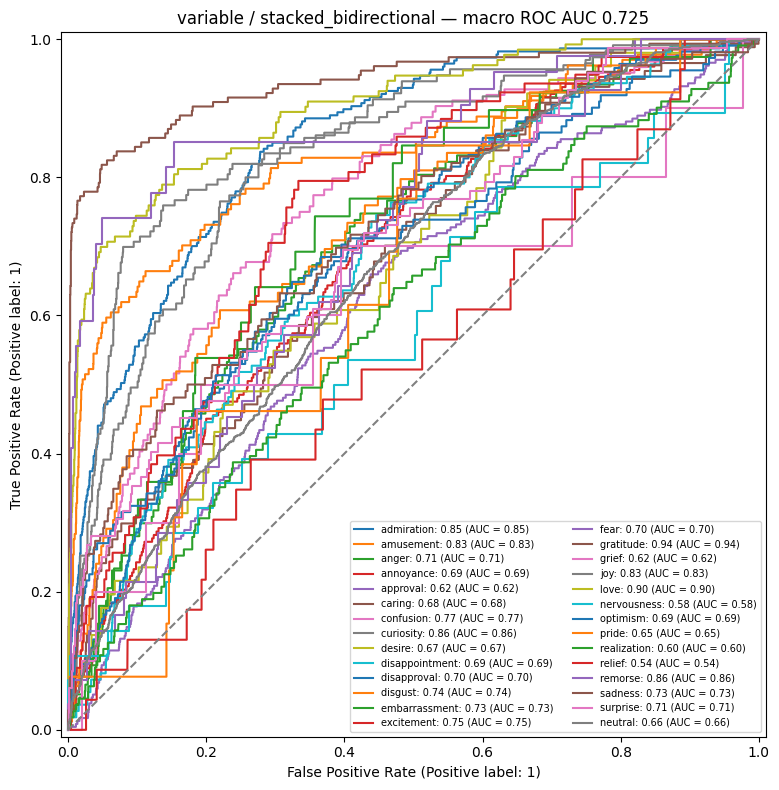

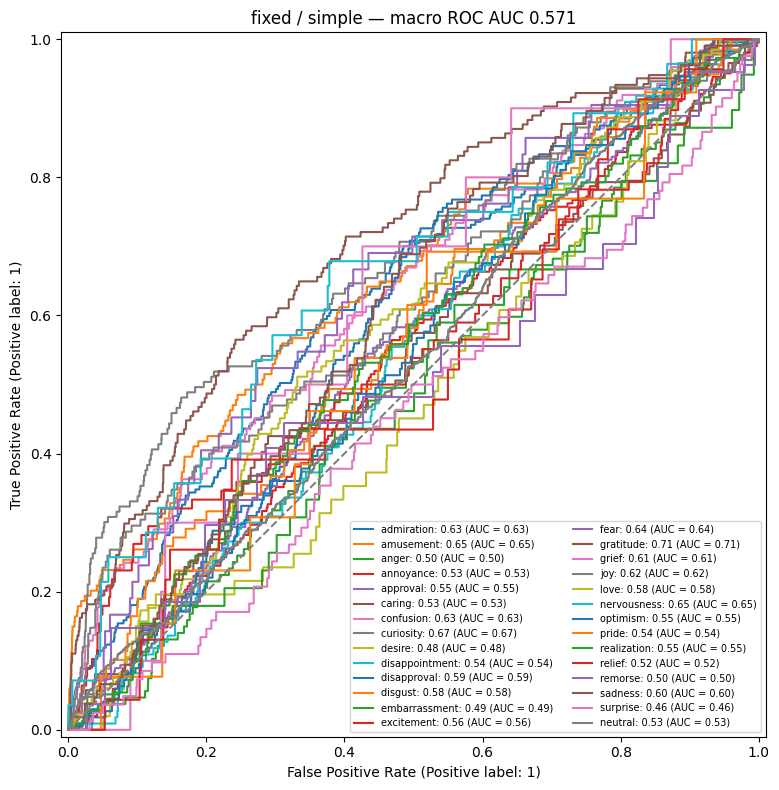

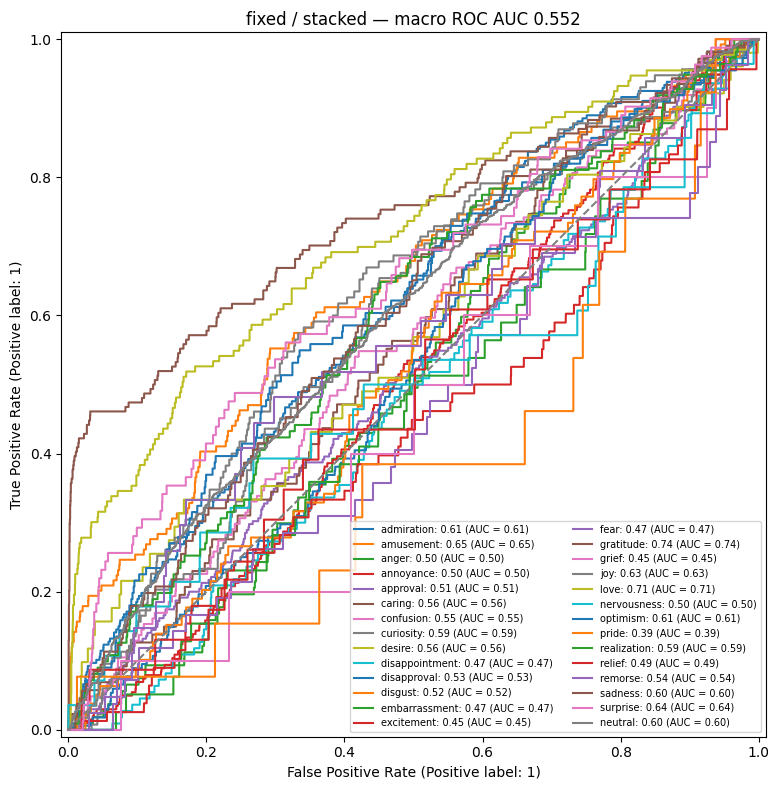

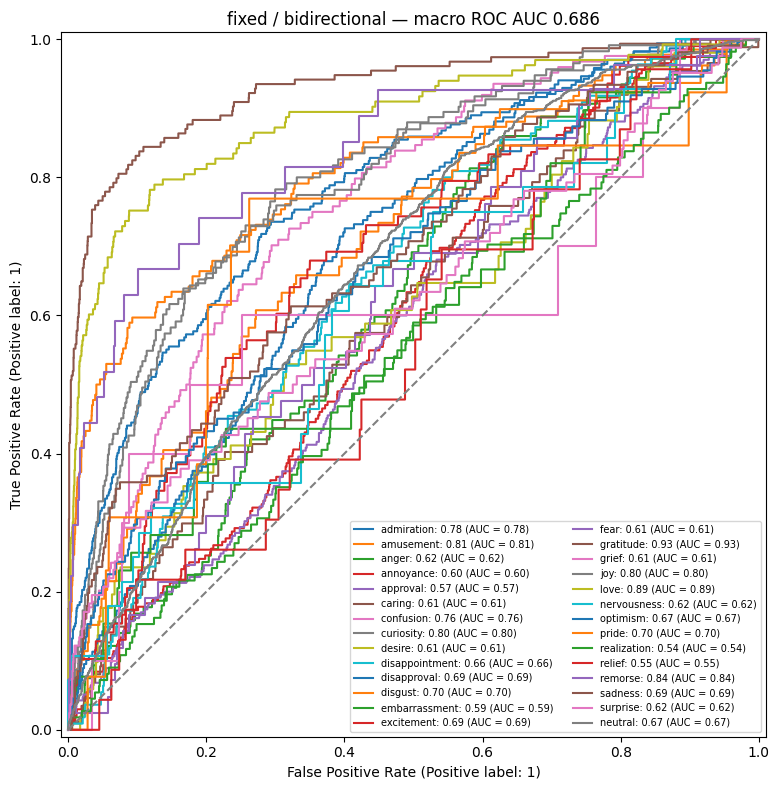

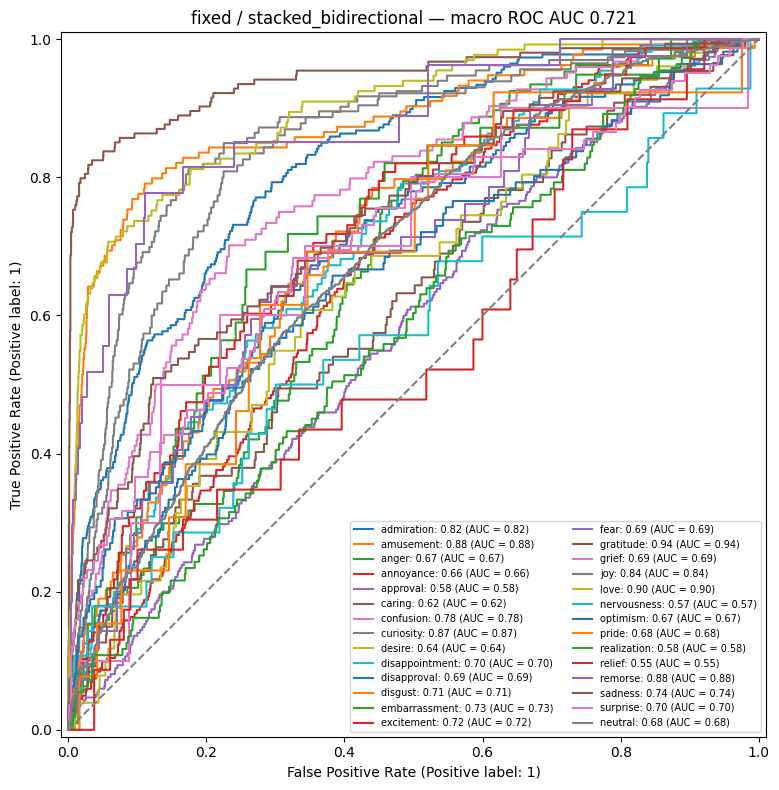

,variant,architecture,macro_roc_auc,micro_roc_auc,micro_f1
3,variable,stacked_bidirectional,0.724701,0.833438,0.173807
7,fixed,stacked_bidirectional,0.721022,0.829372,0.197745
6,fixed,bidirectional,0.686262,0.809208,0.113625
2,variable,bidirectional,0.666900,0.797195,0.102326
1,variable,stacked,0.593069,0.760526,0.000000
4,fixed,simple,0.571063,0.745920,0.000000
0,variable,simple,0.561164,0.742444,0.000564
5,fixed,stacked,0.551584,0.736360,0.000000


In [30]:
def prepare_test_arrays(indices, variant):
    length = FIXED_LENGTH if variant == 'fixed' else min(
        VARIABLE_MAX_LENGTH, max(len(encoded[int(i)]) for i in indices)
    )
    X = np.zeros((len(indices), length), dtype=np.int32)
    for row, i in enumerate(indices):
        tokens = encoded[int(i)][:length]
        X[row, :len(tokens)] = tokens
    return X, labels[indices]

test_arrays = {kind: prepare_test_arrays(idx_test, kind) for kind in splits}
results = []
for (variant, architecture), model in trained_models.items():
    X, y = test_arrays[variant]
    probabilities = model.predict(X, batch_size=BATCH_SIZE, verbose=0)
    valid = np.array([np.unique(y[:, i]).size == 2 for i in range(y.shape[1])])
    macro_auc = sklearn.metrics.roc_auc_score(y[:, valid], probabilities[:, valid], average='macro')
    micro_auc = sklearn.metrics.roc_auc_score(y[:, valid], probabilities[:, valid], average='micro')
    f1 = sklearn.metrics.f1_score(y, probabilities >= 0.5, average='micro', zero_division=0)
    results.append(dict(variant=variant, architecture=architecture, macro_roc_auc=macro_auc,
                        micro_roc_auc=micro_auc, micro_f1=f1))
    fig, ax = plt.subplots(figsize=(11, 8))
    aucs = []
    for j, name in enumerate(emotions):
        if not valid[j]:
            continue
        auc = sklearn.metrics.roc_auc_score(y[:, j], probabilities[:, j])
        aucs.append(auc)
        sklearn.metrics.RocCurveDisplay.from_predictions(
            y[:, j], probabilities[:, j], ax=ax, name=f'{name}: {auc:.2f}'
        )
    ax.plot([0, 1], [0, 1], '--', color='gray')
    ax.set_title(f'{variant} / {architecture} — macro ROC AUC {np.mean(aucs):.3f}')
    ax.legend(fontsize=7, ncol=2, loc='lower right')
    plt.tight_layout()
    plt.show()
results_df = pd.DataFrame(results).sort_values('macro_roc_auc', ascending=False)
display(results_df)

Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

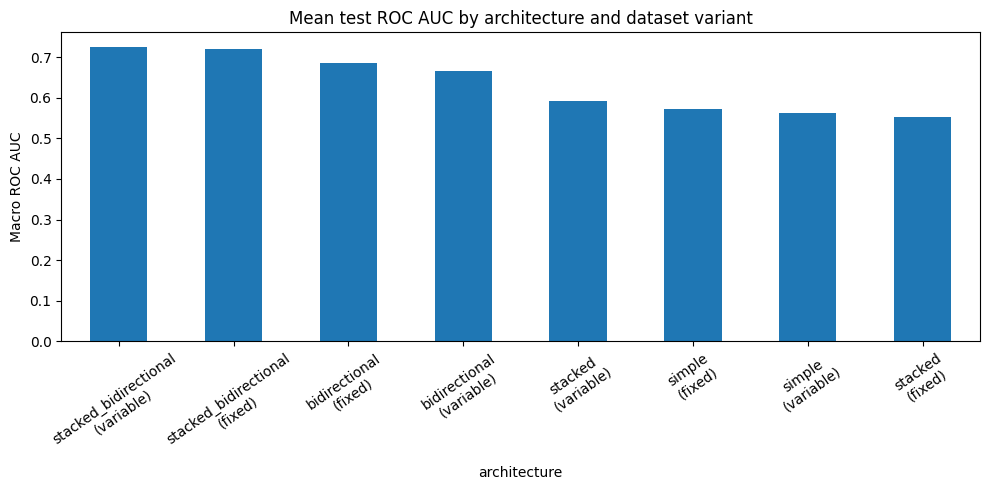

Best: stacked_bidirectional on variable dataset, macro ROC AUC=0.7247


In [31]:
ax = results_df.plot.bar(
    x='architecture', y='macro_roc_auc', figsize=(10, 5), legend=False,
    title='Mean test ROC AUC by architecture and dataset variant', rot=35,
)
ax.set_xticklabels([f"{row.architecture}\n({row.variant})" for row in results_df.itertuples()])
ax.set_ylabel('Macro ROC AUC')
plt.tight_layout()
plt.show()
best_row = results_df.iloc[0]
best_variant, best_architecture = best_row['variant'], best_row['architecture']
best_model = trained_models[(best_variant, best_architecture)]
print(f"Best: {best_architecture} on {best_variant} dataset, "
      f"macro ROC AUC={best_row['macro_roc_auc']:.4f}")

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [32]:
def predict_emotions(text: str, model: keras.Model, max_length: int | None = None) -> np.ndarray:
    length = max_length or (FIXED_LENGTH if best_variant == 'fixed' else VARIABLE_MAX_LENGTH)
    ids = tokenizer.encode(text, add_special_tokens=False, truncation=True, max_length=length)
    ids = [i + 1 for i in (ids or [tokenizer.eos_token_id])]
    x = np.zeros((1, length), dtype=np.int32)
    x[0, :len(ids)] = ids
    return model.predict(x, verbose=0)[0]

def label_text(text: str, model: keras.Model, threshold: float = 0.5,
               max_length: int | None = None) -> list[str]:
    '''Computes the model output for `text` and outputs a list of emotions that have a probability of at least `threshold`

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        List of predicted emotion labels'''
    probabilities = predict_emotions(text, model, max_length)
    return [emotions[i] for i in np.flatnonzero(probabilities >= threshold)]

In [33]:
def plot_emotion_scores(text: str, model: keras.Model, max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use        
        max_length: max length for tokenization
        ax: axes to plot on'''

def plot_emotion_scores(text: str, model: keras.Model,
                        max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use        
        max_length: max length for tokenization
        ax: axes to plot on'''
    probabilities = predict_emotions(text, model, max_length)
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 4))
    order = np.argsort(probabilities)[::-1]
    ax.bar(np.array(emotions)[order], probabilities[order])
    ax.axhline(0.5, color='gray', linestyle='--', label='threshold = 0.5')
    ax.set_ylim(0, 1)
    ax.set_ylabel('Predicted probability')
    ax.set_title(text)
    ax.tick_params(axis='x', rotation=80)
    plt.tight_layout()
    return ax

For each of your texts get a list of emotion labels and plot emotion scores


I am so happy that I passed my exam!
Predicted labels (threshold 0.5): []
Top 3: [('love', 0.202), ('joy', 0.193), ('optimism', 0.164)]


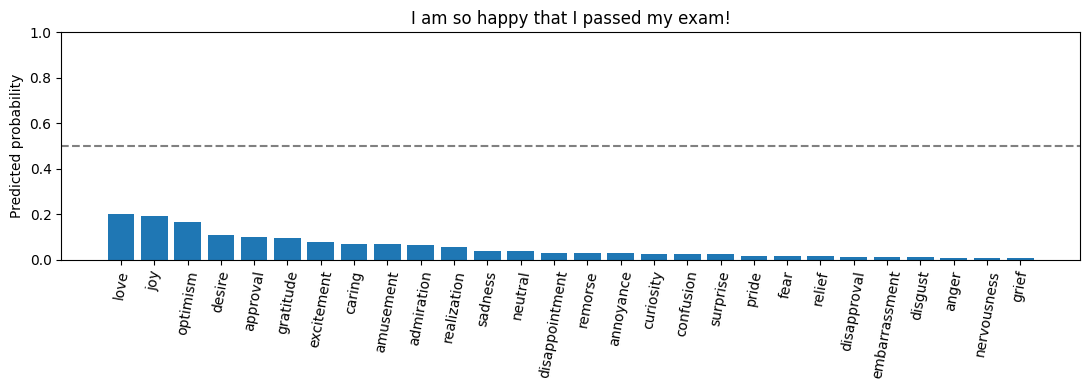


This is absolutely disgusting, I hate it.
Predicted labels (threshold 0.5): []
Top 3: [('disgust', 0.266), ('annoyance', 0.247), ('neutral', 0.219)]


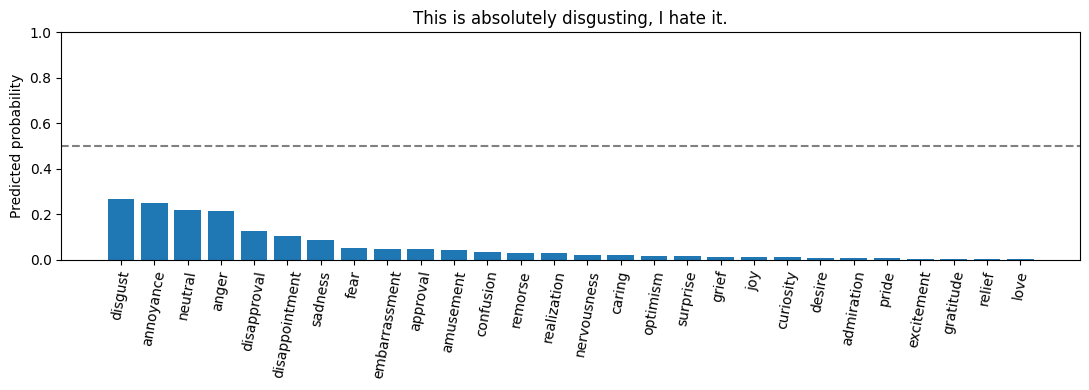


Thank you so much for your help!
Predicted labels (threshold 0.5): ['gratitude']
Top 3: [('gratitude', 0.965), ('admiration', 0.063), ('optimism', 0.051)]


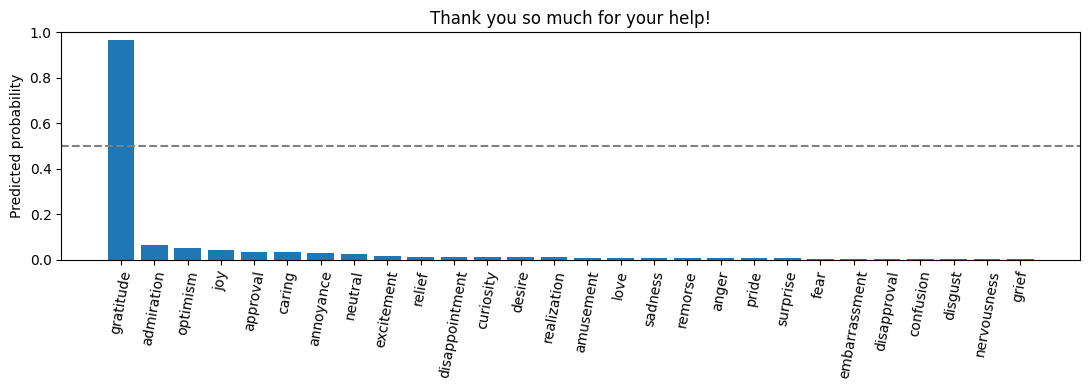


I am nervous about what might happen tomorrow.
Predicted labels (threshold 0.5): []
Top 3: [('neutral', 0.121), ('approval', 0.09), ('confusion', 0.076)]


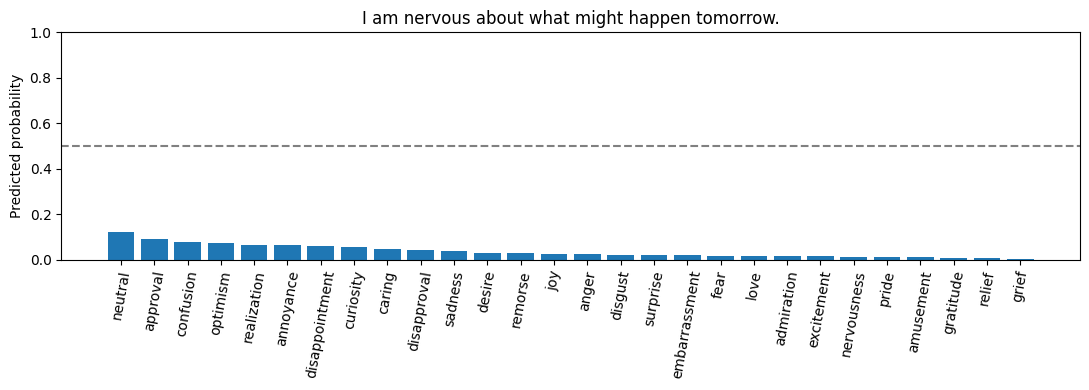


The meeting will be held at noon.
Predicted labels (threshold 0.5): []
Top 3: [('neutral', 0.273), ('admiration', 0.152), ('approval', 0.117)]


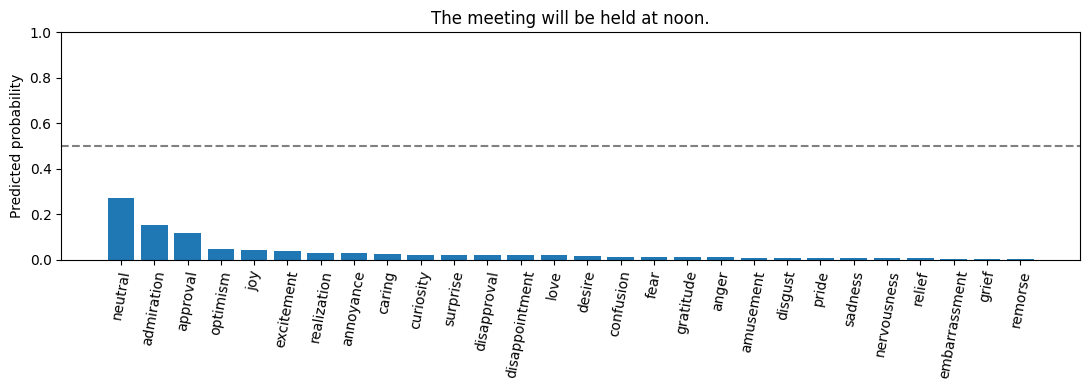

Qualitative note: compare top-scoring emotions against the meaning of each
sentence; rare emotions and neutral may have unreliable probabilities.


In [34]:
examples = [
    'I am so happy that I passed my exam!',
    'This is absolutely disgusting, I hate it.',
    'Thank you so much for your help!',
    'I am nervous about what might happen tomorrow.',
    'The meeting will be held at noon.',
]
for sentence in examples:
    probabilities = predict_emotions(sentence, best_model)
    print(f'\n{sentence}')
    print('Predicted labels (threshold 0.5):', label_text(sentence, best_model))
    print('Top 3:', [(emotions[i], round(float(probabilities[i]), 3))
                     for i in np.argsort(probabilities)[-3:][::-1]])
    fig, ax = plt.subplots(figsize=(11, 4))
    plot_emotion_scores(sentence, best_model, ax=ax)
    plt.show()

print('Qualitative note: compare top-scoring emotions against the meaning of each')
print('sentence; rare emotions and neutral may have unreliable probabilities.')

# Bonus

Train and evaluate the same model as your best one, but use a different cell type

Epoch 1/3
    375/Unknown 14s 21ms/step - binary_accuracy: 0.9419 - loss: 0.2519 - micro_roc_auc: 0.6299

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - binary_accuracy: 0.9547 - loss: 0.1846 - micro_roc_auc: 0.6751 - val_binary_accuracy: 0.9583 - val_loss: 0.1552 - val_micro_roc_auc: 0.7367
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - binary_accuracy: 0.9579 - loss: 0.1593 - micro_roc_auc: 0.7170 - val_binary_accuracy: 0.9577 - val_loss: 0.1543 - val_micro_roc_auc: 0.7497
Epoch 3/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - binary_accuracy: 0.9577 - loss: 0.1564 - micro_roc_auc: 0.7373 - val_binary_accuracy: 0.9583 - val_loss: 0.1508 - val_micro_roc_auc: 0.7643
Original cell: GRUCell macro test ROC AUC: 0.7247010452748059
Alternative cell: LSTMCell macro test ROC AUC: 0.6241114543387106


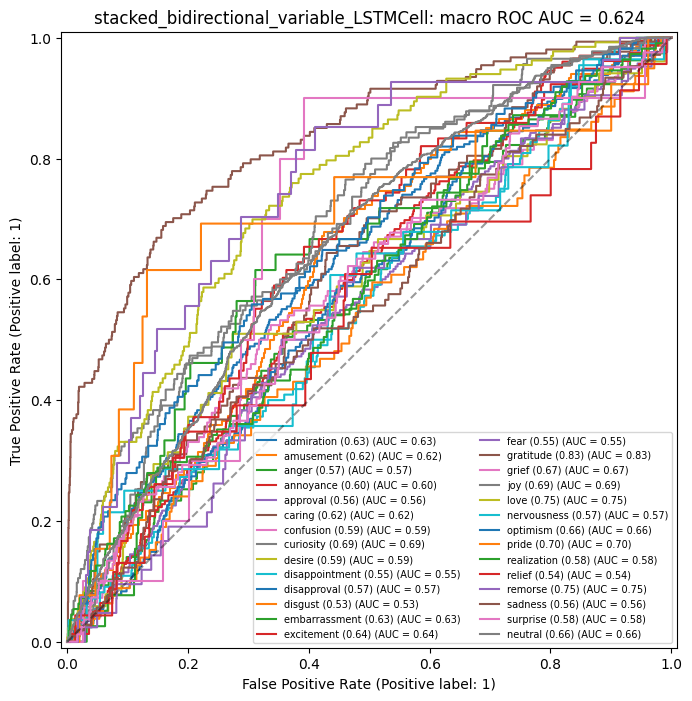

In [35]:
alternative_cell = (keras.layers.LSTMCell if CELL_TYPE is keras.layers.GRUCell
                    else keras.layers.GRUCell)
winning_spec = next(s for s in ARCHITECTURES if s['name'] == best_architecture)
alternative_model = compile_model(get_model(
    units=UNITS, n_tokens=VOCAB_SIZE, n_labels=len(emotions),
    name=f'{best_architecture}_{best_variant}_{alternative_cell.__name__}',
    n_stacks=winning_spec['n_stacks'],
    bidirectional=winning_spec['bidirectional'], cell_type=alternative_cell,
))
alternative_model.fit(
    splits[best_variant]['train'], validation_data=splits[best_variant]['val'],
    epochs=EPOCHS, callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=2, restore_best_weights=True
    )], verbose=1,
)
X_test, y_test = test_arrays[best_variant]
alt_probs = alternative_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
valid = np.array([np.unique(y_test[:, i]).size == 2 for i in range(y_test.shape[1])])
alt_auc = sklearn.metrics.roc_auc_score(y_test[:, valid], alt_probs[:, valid], average='macro')
print('Original cell:', CELL_TYPE.__name__, 'macro test ROC AUC:', float(best_row['macro_roc_auc']))
print('Alternative cell:', alternative_cell.__name__, 'macro test ROC AUC:', alt_auc)
fig, ax = plt.subplots(figsize=(11, 8))
plot_roc_curve(X_test, y_test, alternative_model, ax=ax)
plt.show()